# Reproducing the paper, item by item

*Neutral-Atom Quantum Features as Complementary Structural Encodings for Graph Learning* (NeurIPS 2026).

**How to read this notebook**
- Items follow the paper order, then the additional experiments.
- Each item gives:
  - **Shows**: the claim;
  - **Reported**: the published numbers;
  - **This repository**: how closely the re-run reproduces it (bit-identical or within re-training noise);
  - **Run** / **Caveats** / **Results**: commands, environment and hardware notes, and where the files are.
- Two code cells follow each item:
  - the first recomputes it **from precomputed inputs** (released features, stored per-trial results; minutes on a laptop CPU);
  - the second shows the result (the fresh one, else the stored reference).
- Re-training and re-emulation (GPU / Slurm grids) are given as commands only.

**Open:** `uv run --with jupyter jupyter lab reproduce/walkthrough.ipynb` from the repository root.

**Data**
- Features: `uv run python -m qgf.data.download` (Zenodo, DOI 10.5281/zenodo.23099924) -> `data/processed`.
- Raw counts (only for the App. D cells): `--files qgf_raw.tar`, extracted to `data/raw`.
- Correlations are stored in the ZZ convention (`4 C`), time-major (`[T, N]`, `[T, N, N]`).

**Environments**
- **Project** (`uv sync [--extra ...]`): everything; numbers match the paper statistically.
- **Pinned, `reproduce/paper_env`**: bit-identical trials of the downstream GNNs, ESA, ablations and non-unit-disk.
  - Setup: `uv sync --frozen --project reproduce/paper_env` once.
  - Run: `PYTHONPATH=src uv run --frozen --project reproduce/paper_env python ...`.
  - Slurm wrappers: `GNN_ENV=paper`, `ESA_ENV=paper`, `ABL_ENV=paper`.
- Bit-identity also needs the hardware and thread count of the original runs:
  - GPU items: an A100;
  - CPU items: **AMD EPYC 7742** nodes without GPU (cluster: `-p internal` without `--gres`; the AVX-512 EPYC 9654 nodes change the last bits);
  - 1 or 4 threads per process, given per item below.

**Status**
- **Bit-identical re-run:** Table 4 (ESA); Tables 2-3 GNN columns with the geometry and hardware tables; Tables 8-10; non-unit-disk; Fig. 2; App. G inputs.
- **Within the stated tolerance:** Table 1, Tables 11-15, Tables 2-3 GT column, Figs. 4-5, App. D, reconstruction, placement.
- **From stored trials only:** Fig. 6.
- **Not in this release:** Figs. 1 and 3, App. B-C (physics).

In [1]:
# Setup: run from the repository root; RUN = False only shows the stored results.
import json
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "reproduce" else Path.cwd()
os.chdir(ROOT)
DATA = Path(os.environ.get("QGF_DATA", "data/processed"))
RAW = Path("data/raw")
RUN = True  # recompute the items from the precomputed inputs (CPU, minutes)


def run(*args, needs=()):
    """``python <args>`` in the notebook's environment, if its inputs are present."""
    missing = [str(p) for p in needs if not Path(p).exists()]
    if missing:
        print("skipped (missing input: " + ", ".join(missing) + ")")
        return
    print("$ python " + " ".join(map(str, args)))
    if RUN:
        r = subprocess.run([sys.executable, *map(str, args)], capture_output=True, text=True)
        lines = [ln for ln in (r.stdout + r.stderr).splitlines() if "warn" not in ln.lower()]
        print("\n".join(lines)[-2000:] or "done")


def show(*paths, n=None):
    """Show the first existing file (fresh result, else the stored reference)."""
    p = next((Path(x) for x in paths if Path(x).exists()), None)
    if p is None:
        print("not found:", ", ".join(map(str, paths)))
        return
    print(p)
    if p.suffix == ".csv":
        df = pd.read_csv(p)
        display(df.head(n) if n else df)
    elif p.suffix == ".json":
        print(json.dumps(json.loads(p.read_text()), indent=1)[:3000])
    elif p.suffix == ".md":
        display(Markdown(p.read_text()))
    elif p.suffix == ".png":
        display(Image(str(p)))
    else:
        print(p.read_text()[:4000])

## 1. Quantum graph features (Sec. 2, App. D)

### Feature generation, App. D.1
- **Shows:** the AFM / FM quench of an embedded register gives the released features.
- **This repository:** features rebuilt from the released raw counts equal the released ones (max difference 0); ZINC\*<sub>subset</sub> = the 11 368 of 11 494 embeddable ZINC graphs.
- **Re-emulate (GPU, optional):** `uv run --extra generate python experiments/generation/run.py --dataset mutag_afm --pulse afm --start 0 --end 4 --out results/generation/x --features`.
- **Caveats:**
  - emulating all of ZINC costs ~800 A100 GPU-days;
  - new graphs: embed with Blade (`qoolqit.embedding.Blade`).
- **Results:** `experiments/generation/expected/` (`validate_raw.json`, `validate_emulation.json`, `zinc_subset.json`).

In [2]:
run("experiments/generation/validate_raw.py", needs=[RAW / "emulation"])

skipped (missing input: data/raw/emulation)


In [3]:
show("results/generation/validate_raw.json", "experiments/generation/expected/validate_raw.json")

experiments/generation/expected/validate_raw.json
{
 "mutag_afm": {
  "graphs": 188,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "mutag_fm": {
  "graphs": 188,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "mutag_hw_afm": {
  "graphs": 188,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_afm_test": {
  "graphs": 947,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_afm_train": {
  "graphs": 9475,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_afm_val": {
  "graphs": 946,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_fm_test": {
  "graphs": 947,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_fm_train": {
  "graphs": 9475,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 },
 "zinc_fm_val": {
  "graphs": 946,
  "max_abs_diff": {
   "onebody": 0.0,
   "twobody": 0.0
  }
 }
}


### Temporal PCA, Fig. 4 / App. D.2
- **Shows:** most of the feature variance lives in a few temporal components.
- **Reported:** ZINC AFM one-body PC1 80.6 %, two-body PC1 59.4 %.
- **This repository:** within 1.1e-5 of the reference run.
- **Results:** `results/temporal_pca/pca_<ds>.{json,png}`; reference `experiments/temporal_pca/expected/`. The cell runs MUTAG (fast); ZINC: `--dataset zinc`.

In [4]:
run(
    "experiments/temporal_pca/run.py",
    "--dataset",
    "mutag",
    needs=[DATA / "mutag_afm.pt", DATA / "mutag_fm.pt"],
)

$ python experiments/temporal_pca/run.py --dataset mutag


mutag afm onebody [3371, 20]: PC1 82.5%, PC2 4.7%, PC3 1.9%, components {'80%': 1, '90%': 4, '95%': 10, '99%': 18}
mutag afm twobody [7442, 20]: PC1 64.6%, PC2 8.4%, PC3 5.6%, components {'80%': 4, '90%': 10, '95%': 14, '99%': 19}
mutag fm onebody [3371, 20]: PC1 87.4%, PC2 4.8%, PC3 1.5%, components {'80%': 1, '90%': 2, '95%': 5, '99%': 16}
mutag fm twobody [7442, 20]: PC1 71.9%, PC2 5.0%, PC3 3.0%, components {'80%': 4, '90%': 10, '95%': 15, '99%': 19}
wrote results/temporal_pca/pca_mutag.json/.png


results/temporal_pca/pca_mutag.json
{
 "afm": {
  "onebody": {
   "shape": [
    3371,
    20
   ],
   "var_ratio": [
    0.8252589702606201,
    0.046936001628637314,
    0.01893400028347969,
    0.013883000239729881,
    0.011982000432908535,
    0.009476999752223492,
    0.0075240000151097775,
    0.007391999941319227,
    0.006678000092506409,
    0.006194000132381916,
    0.0060259997844696045,
    0.005630000028759241,
    0.005342999938875437,
    0.0050860000774264336,
    0.004592999815940857,
    0.004222000017762184,
    0.004155999980866909,
    0.003828000044450164,
    0.00367900007404387,
    0.0031799999997019768
   ],
   "n_components": {
    "80%": 1,
    "90%": 4,
    "95%": 10,
    "99%": 18
   }
  },
  "twobody": {
   "shape": [
    7442,
    20
   ],
   "var_ratio": [
    0.6456720232963562,
    0.08372300118207932,
    0.056494999676942825,
    0.03044299967586994,
    0.01865999959409237,
    0.017954999580979347,
    0.016683999449014664,
    0.0143870003521442

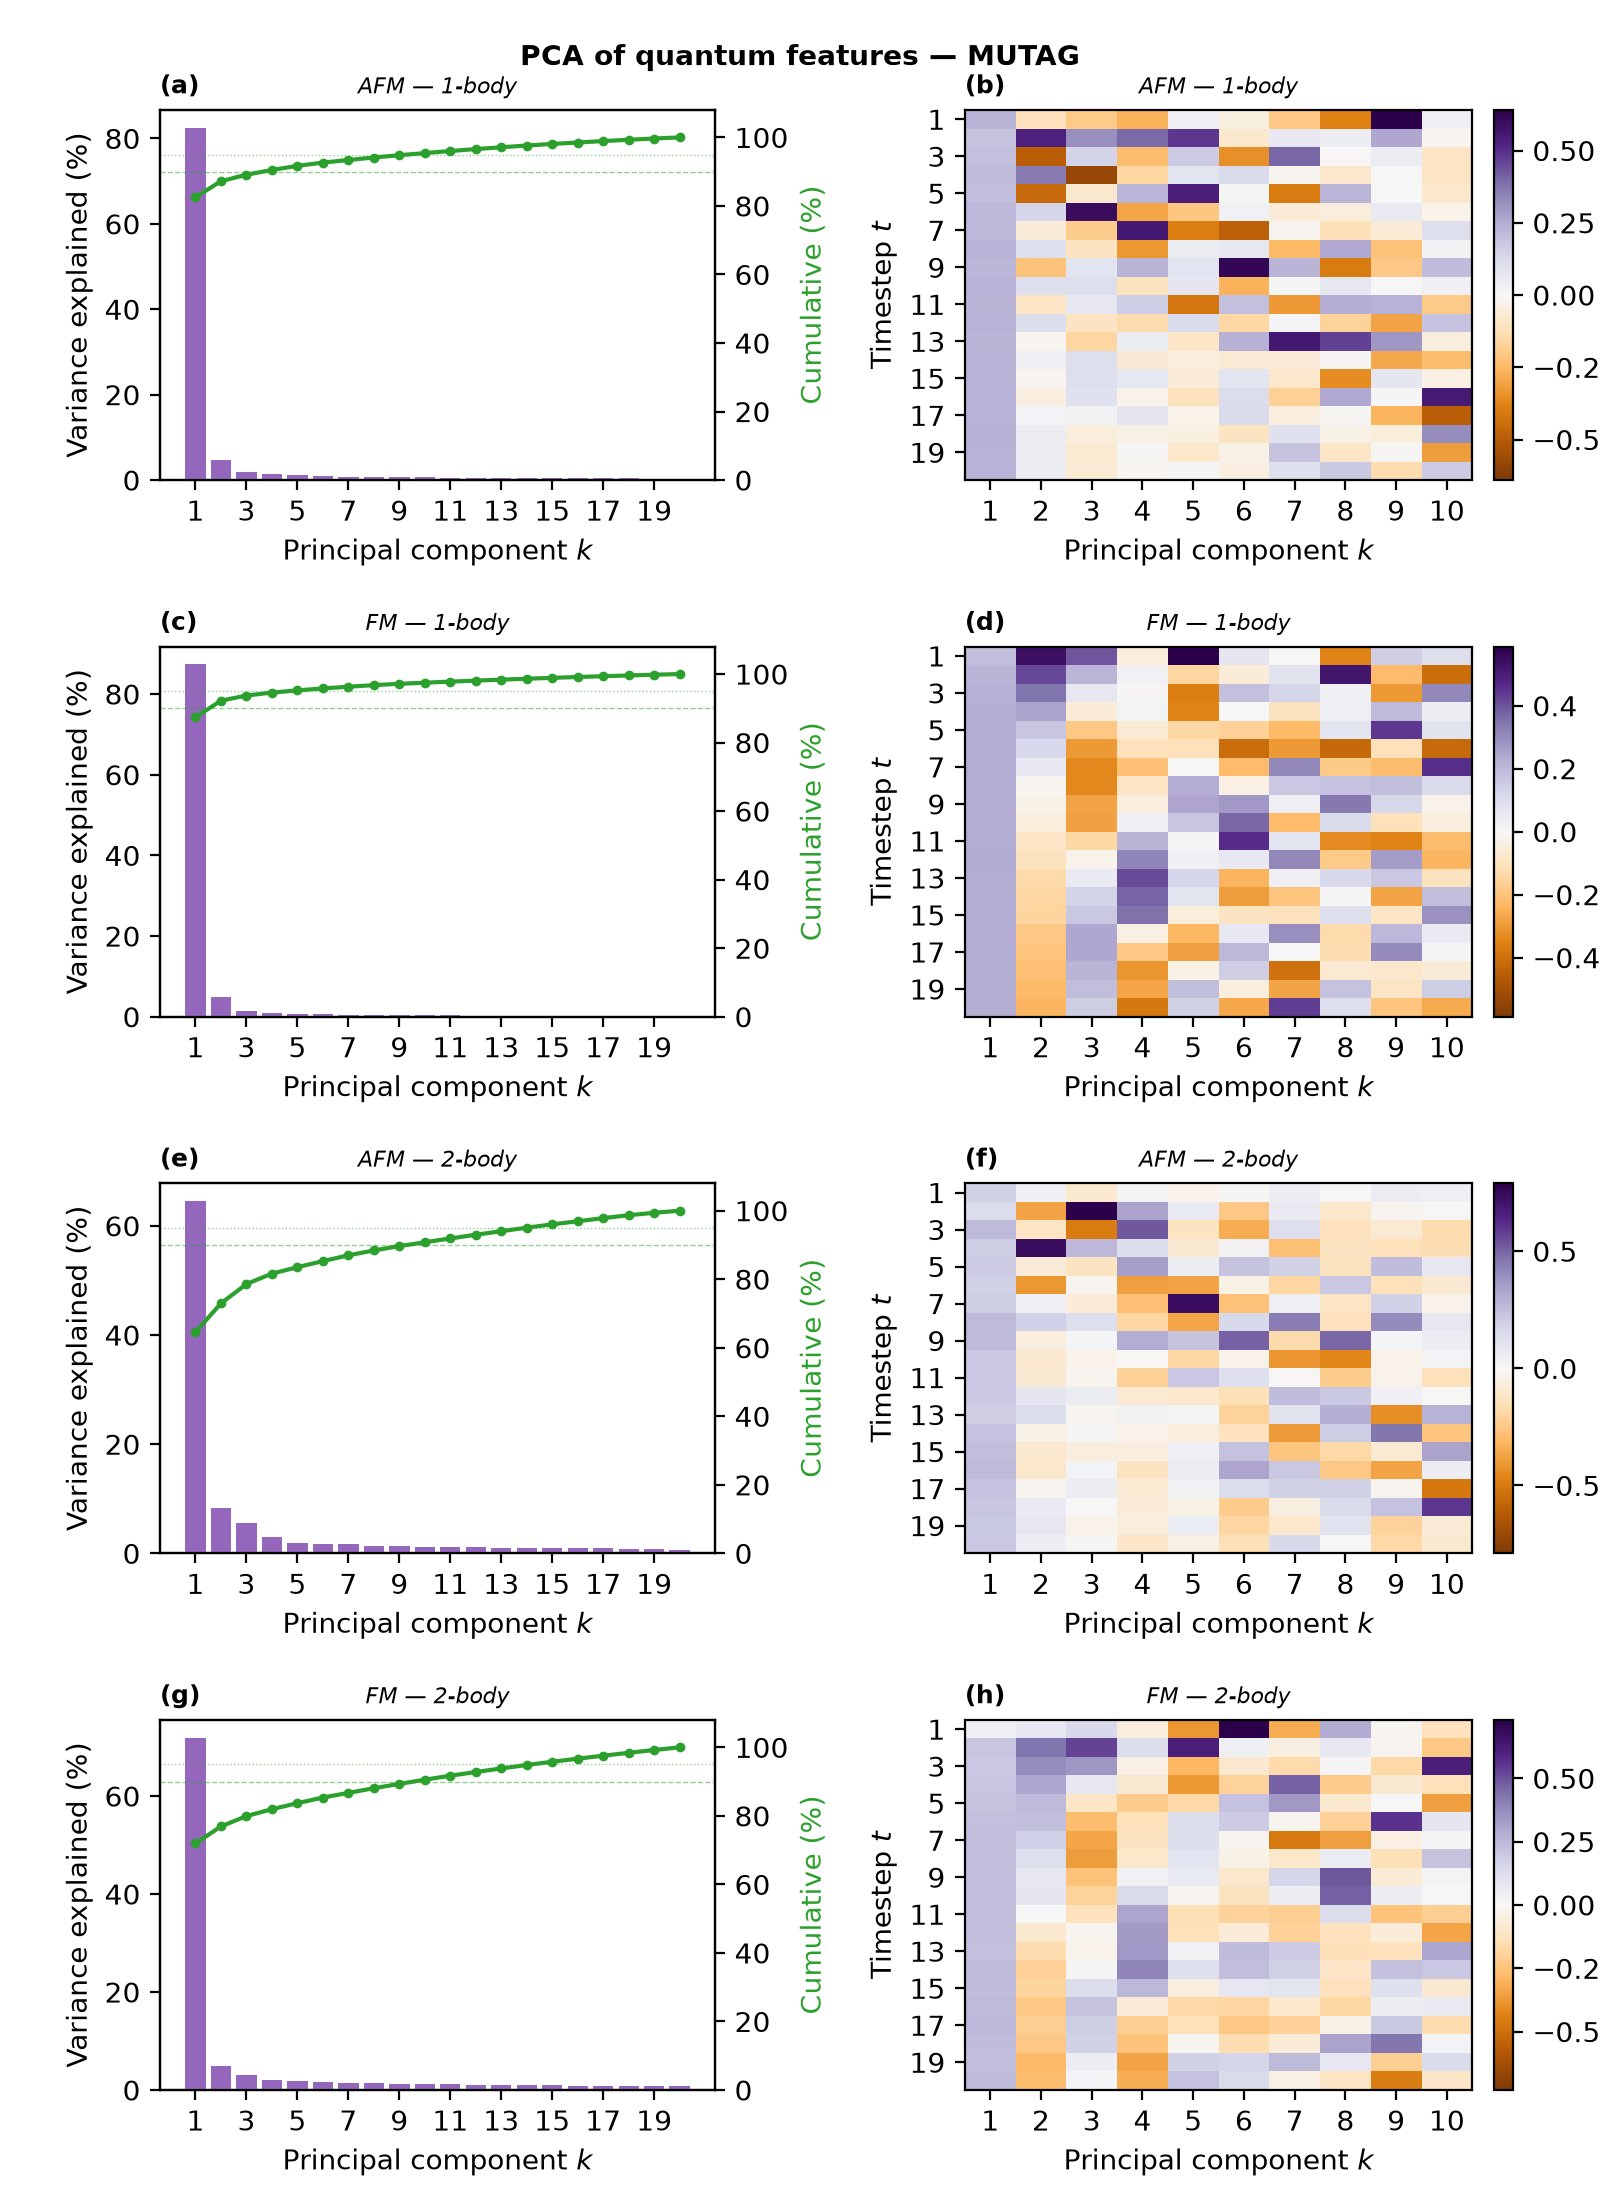

In [5]:
show("results/temporal_pca/pca_mutag.json", "experiments/temporal_pca/expected/pca_mutag.json")
show("results/temporal_pca/pca_mutag.png")

### Shot budget, App. D.3
- **Shows:** how many shots the correlation estimates need.
- **Reported:** ~875 shots at N = 18 (734-983 per graph).
- **Results:** `experiments/shot_budget/expected/shot_budget.json` (needs `data/raw`).

In [6]:
run("experiments/shot_budget/run.py", needs=[RAW / "emulation"])

skipped (missing input: data/raw/emulation)


In [7]:
show("results/shot_budget/shot_budget.json", "experiments/shot_budget/expected/shot_budget.json")

experiments/shot_budget/expected/shot_budget.json
{
 "formula": [
  {
   "N": 10,
   "M": 55,
   "k_N": 3.317247361552435,
   "shots": 734
  },
  {
   "N": 11,
   "M": 66,
   "k_N": 3.367847180032717,
   "shots": 757
  },
  {
   "N": 12,
   "M": 78,
   "k_N": 3.4136342659485033,
   "shots": 777
  },
  {
   "N": 13,
   "M": 91,
   "k_N": 3.4554129663390474,
   "shots": 796
  },
  {
   "N": 14,
   "M": 105,
   "k_N": 3.4938040039432683,
   "shots": 814
  },
  {
   "N": 15,
   "M": 120,
   "k_N": 3.5292960888347347,
   "shots": 831
  },
  {
   "N": 16,
   "M": 136,
   "k_N": 3.5622806462286185,
   "shots": 846
  },
  {
   "N": 17,
   "M": 153,
   "k_N": 3.5930758684962227,
   "shots": 861
  },
  {
   "N": 18,
   "M": 171,
   "k_N": 3.6219437933465697,
   "shots": 875
  },
  {
   "N": 19,
   "M": 190,
   "k_N": 3.6491026963009765,
   "shots": 888
  },
  {
   "N": 20,
   "M": 210,
   "k_N": 3.674736256384331,
   "shots": 901
  },
  {
   "N": 21,
   "M": 231,
   "k_N": 3.6990004509523953,
  

### QPU vs emulation, Fig. 5 / App. D.4
- **Shows:** QPU features track the emulation.
- **Reported:** per-graph Spearman median, one-body 0.921, two-body 0.870.
- **Caveats:**
  - the QPU run cannot be repeated from here; `mutag_hw_afm` holds its features;
  - the hardware run combines four measurement times (~0.3-4 us), not a single time step.
- **Results:** `experiments/qpu_vs_emulation/expected/fig5.json` (needs `data/raw`).

In [8]:
run("experiments/qpu_vs_emulation/run.py", needs=[RAW / "qpu"])

skipped (missing input: data/raw/qpu)


In [9]:
show("results/qpu_vs_emulation/fig5.json", "experiments/qpu_vs_emulation/expected/fig5.json")
show("results/qpu_vs_emulation/fig5.png")

experiments/qpu_vs_emulation/expected/fig5.json
{
 "shots_qpu": [
  861,
  796,
  796,
  888,
  757,
  983,
  846,
  901,
  777,
  861,
  861,
  901,
  924,
  796,
  888,
  924,
  757,
  861,
  796,
  875,
  875,
  861,
  935,
  974,
  861,
  796,
  935,
  861,
  935,
  935,
  924,
  945,
  935,
  796,
  861,
  814,
  861,
  831,
  831,
  796,
  861,
  796,
  888,
  861,
  777,
  935,
  924,
  861,
  901,
  846,
  965,
  965,
  888,
  888,
  814,
  861,
  913,
  955,
  935,
  888,
  861,
  757,
  935,
  901,
  846,
  846,
  901,
  935,
  888,
  814,
  965,
  846,
  846,
  935,
  875,
  734,
  846,
  846,
  861,
  888,
  777,
  955,
  846,
  758,
  935,
  935,
  846,
  777,
  796,
  935,
  955,
  888,
  935,
  888,
  888,
  955,
  875,
  796,
  831,
  846,
  935,
  965,
  888,
  935,
  861,
  901,
  955,
  888,
  983,
  945,
  757,
  831,
  796,
  846,
  777,
  734,
  913,
  935,
  913,
  796,
  955,
  913,
  861,
  757,
  888,
  901,
  913,
  831,
  814,
  757,
  888,
  758,
  913,
  9

## 2. Linear recovery on a toy dataset (Fig. 2)
- **Shows:** adjacency powers / RRWP linearly recover the quantum correlations only at early times; afterwards the correlations leave their span.
- **This repository:** all 720 curve values equal the published run (bit-identical).
- **Caveats:** the toy graphs are the two MUTAG graphs with N = 10 (ids 75, 115); the default settings of `fig2.py` reproduce the published curves.
- **Results:** `experiments/reconstruction/expected/fig2_r2_{published,paper}.csv`; figure `results/reconstruction/fig2/fig2_recovery_published.pdf`.

In [10]:
run(
    "experiments/reconstruction/fig2.py",
    "--out",
    "results/reconstruction/fig2",
    needs=[DATA / "mutag_afm.pt"],
)

$ python experiments/reconstruction/fig2.py --out results/reconstruction/fig2


MUTAG graphs with N = 10: [75, 115]
K                   1      3      7      21
pulse family                               
AFM   adjacency  0.465  0.796  0.800  0.811
      rrwp       0.466  0.836  0.838  0.858
FM    adjacency  0.027  0.328  0.363  0.403
      rrwp       0.022  0.160  0.208  0.434


In [11]:
p = next(
    x
    for x in [
        "results/reconstruction/fig2/fig2_r2_published.csv",
        "experiments/reconstruction/expected/fig2_r2_published.csv",
    ]
    if Path(x).exists()
)
c = pd.read_csv(p)
print(p, "- pooled R^2 at 400 ns")
display(
    c[(c.t_ns == c.t_ns.max()) & c.K.isin([1, 3, 7, 21])]
    .pivot_table(index=["pulse", "family"], columns="K", values="r2")
    .round(3)
)

results/reconstruction/fig2/fig2_r2_published.csv - pooled R^2 at 400 ns


K                   1      3      7      21
pulse family                               
AFM   adjacency  0.465  0.796  0.800  0.811
      rrwp       0.466  0.836  0.838  0.858
FM    adjacency  0.027  0.328  0.363  0.403
      rrwp       0.022  0.160  0.208  0.434

## 3. Intrinsic benchmark (Sec. 3.1, Table 1; App. F, Tables 11-12)
- **Shows:** a DeepSet probe on 15 graph-theoretic tasks; RRWP + QGF hybrids are the most informative feature sets.
- **Reported (paper):** degree MAE x10^2: RRWP 14.4, AFM 1.26, RRWP+FM+AFM 1.25.
- **Reported (strengthened baseline RRWP + Laplacian + Rings + r + J):**
  - QGFs still add information on four tasks; none is degraded; eight end in a statistical tie; three are excluded (their targets follow from the ring descriptors);
  - residual on top of the geometry baseline wins on eccentricity (0.616 ± 0.003 vs 0.628 ± 0.009) and local connectivity (0.022 ± 0.000 vs 0.027 ± 0.001).
- **This repository:** GPU re-training is not bit-identical; cells agree within re-training noise (about one fold std). Reference re-runs: `ZINC_small_table_main.md`, `ZINC_quantum_comparison.md`, `ZINC_residual_comparison.md`.
- **Re-train (GPU grid):** `experiments/intrinsic/submit_grid.sh`, then `uv run python -m qgf.intrinsic.tables --results_dir results/intrinsic/grid --out_dir results/intrinsic/tables`.
- **Results:** `experiments/intrinsic/expected/` (Table 1 `ZINC_small_table_main.md`; Tables 11-12 `*_table_full.md`; `ZINC_quantum_comparison.md`, `ZINC_residual_comparison.md`).

In [12]:
show(
    "results/intrinsic/tables/ZINC_small_table_main.md",
    "experiments/intrinsic/expected/ZINC_small_table_main.md",
)

experiments/intrinsic/expected/ZINC_small_table_main.md


# Intrinsic information benchmark on ZINC*_subset (main table, means over 5 folds)

**bold**: best, *italic*: runner-up, ≈: statistically tied with the best (|v_best − v| ≤ σ_best + 0.005·|v_best|). ↓ MAE, ↑ accuracy. Random is not ranked.

| Task | RRWP | Laplacian | RRWP+Lap. | FM_stat | FM | AFM_stat | AFM | RRWP+FM | RRWP+AFM | RRWP+FM+AFM |
|---|---|---|---|---|---|---|---|---|---|---|
| *Node Prediction* | | | | | | | | | | |
| Bridge Node ↑ | 0.93 | 0.76 | 0.95 | 0.74 | 0.83 | 0.85 | 0.91 | 0.97 | 0.98 ≈ | 0.98 ≈ |
| Degree ↓ (×10²) | 14.4 | 46.7 | 6.98 | 30.5 | 18.7 | 9.07 | 1.26 ≈ | 4.71 | 1.18 ≈ | 1.25 ≈ |
| Betweenness ↓ (×10²) | 7.77 | 12.5 | 4.76 | 9.10 | 7.17 | 10.1 | 7.11 | 4.33 | *3.90* | **3.31** |
| Eccentricity ↓ | 1.88 | 1.51 | **1.08** | 1.90 | 1.65 | 2.02 | 1.91 | 1.48 | 1.77 | *1.47* |
| Min Cycle (Node) ↓ | 0.73 | 1.68 | 0.60 | 1.80 | 1.42 | 1.40 | 0.88 | 0.48 | *0.36* | **0.28** |
| *Edge Prediction* | | | | | | | | | | |
| Link Pred. ↑ | 1.00 ≈ | 0.94 | 1.00 ≈ | 0.99 | 0.99 | 1.00 ≈ | 1.00 ≈ | 1.00 ≈ | 1.00 ≈ | 1.00 ≈ |
| Bridge Edge ↑ | 0.99 ≈ | 0.98 | 0.99 ≈ | 0.97 | 0.98 | 0.97 | 0.99 | 0.99 ≈ | 0.99 ≈ | 1.00 ≈ |
| Edge Betw. ↓ (×10³) | 11.6 | 20.6 | *6.09* | 13.0 | 9.89 | 9.76 | 8.61 | 6.69 | 6.13 | **5.36** |
| Local Conn. ↓ (×10²) | 10.0 | 13.9 | 7.39 | 13.9 | 12.6 | 15.2 | 11.3 | 6.83 | *6.07* | **5.14** |
| Min Cycle (Edge) ↓ (×10²) | 13.3 | 42.4 | 10.2 | 23.0 | 19.4 | 23.1 | 13.2 | 10.0 | 7.62 ≈ | 7.17 ≈ |
| *Graph Prediction* | | | | | | | | | | |
| Num Cycles ↓ (×10²) | 6.68 | 27.4 | 5.90 | 18.4 | 15.3 | 16.4 | 9.85 | 4.83 ≈ | 4.48 ≈ | 4.67 ≈ |
| Diameter ↓ | 0.49 | 0.69 | 0.47 | 0.71 | 0.65 | 0.75 | 0.60 | *0.36* | 0.37 | **0.32** |
| Density ↓ (×10³) | 1.03 ≈ | 2.48 | 1.14 ≈ | 1.86 | 1.70 | 1.72 | 1.86 | 1.21 ≈ | 1.10 ≈ | 1.25 ≈ |
| Wiener Index ↓ (×10²) | 10.8 | 19.2 | 9.61 | 16.4 | 14.1 | 19.5 | 15.0 | 7.13 ≈ | 8.81 | 7.24 ≈ |
| Alg. Connect. ↓ (×10³) | 2.63 | 5.59 | 2.22 ≈ | 5.46 | 5.21 | 6.30 | 5.32 | 2.70 | 2.34 ≈ | 2.38 |


## 4. Classical reconstruction ceiling (Sec. 3.2; App. H, Tables 13-15)
- **Shows:** even an extended classical basis (walk powers, RRWP, Laplacian, rings, heat kernel, shortest paths, effective resistance, register geometry r and J, dTWA, exact two-atom and mean-field responses) leaves part of the quantum dynamics unexplained; the residual is released and analysed.
- **Reported:**
  - unexplained variance 8.84 % (AFM) and 13.3 % (FM);
  - the combined AFM+FM residual retains 97.4 % of the full matrices' predictive performance on graph-level tasks;
  - correlation with graph invariants: mean |corr| 0.46 (graph), 0.33 (edge), 0.17 (node).
- **This repository:**
  - the ceiling run gives the unexplained variance per basis family and probe (`ceiling_summary_mutag.csv`);
  - residual retention on graph-level tasks: 97.4 %;
  - the correlation with graph invariants is not part of this release.
- **Run:** `uv run python experiments/reconstruction/run.py ceiling` (CPU, long); Tables 13-15: `uv run python -m qgf.reconstruction.run sweep ...`; residuals: `uv run python experiments/reconstruction/run.py residual-analysis`.
- **Results:** `experiments/reconstruction/expected/` (`ceiling_summary_mutag.csv`, Tables 13-15, residual analysis).

In [13]:
show(
    "results/reconstruction/ceiling/ceiling_summary.csv",
    "experiments/reconstruction/expected/ceiling_summary_mutag.csv",
)
show("experiments/reconstruction/expected/table13_ols_time_averaged.csv", n=10)

experiments/reconstruction/expected/ceiling_summary_mutag.csv


,step,family,probe,quench,r2_ref,r2_time_avg,fold_std_ref,unexplained_ref
0,0,walk,ols,AFM,0.833347,0.824555,NaN,0.166653
1,1,walk+rrwp,ols,AFM,0.868376,0.859483,NaN,0.131624
2,2,walk+rrwp+laplacian,ols,AFM,0.869523,0.860542,NaN,0.130477
3,3,walk+rrwp+laplacian+ring,ols,AFM,0.874256,0.866184,NaN,0.125744
4,4,walk+rrwp+laplacian+ring+heat+geodesic+resistance,ols,AFM,0.896566,0.892794,NaN,0.103434
5,5,walk+rrwp+laplacian+ring+heat+geodesic+resista...,ols,AFM,0.896574,0.893041,NaN,0.103426
6,6,walk+rrwp+laplacian+ring+heat+geodesic+resista...,ols,AFM,0.896667,0.894014,NaN,0.103333
7,7,walk+rrwp+laplacian+ring+heat+geodesic+resista...,ols,AFM,0.896702,0.894446,NaN,0.103298
8,8,walk+rrwp+laplacian+ring+heat+geodesic+resista...,ols,AFM,0.897472,0.896371,NaN,0.102528
9,0,walk,ols,FM,0.700999,0.716742,NaN,0.299001


experiments/reconstruction/expected/table13_ols_time_averaged.csv


,run,dataset,quench,family,k,r2
0,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,1,0.5782
1,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,3,0.7996
2,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,5,0.8036
3,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,7,0.8115
4,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,10,0.8253
5,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,14,0.8321
6,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,21,0.8359
7,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,30,0.8389
8,mutag/p1/ols_intercept,MUTAG,AFM,rrwp,50,0.8392
9,mutag/p1/ols_intercept,MUTAG,AFM,rrwp+laplacian,1,0.5850


## 5. Downstream benchmark (Sec. 4.1, Tables 2-3)

### Graph-transformer column
- **Shows:** GT with RRWP / quantum / hybrid encodings on MUTAG (macro-F1) and ZINC\*<sub>subset</sub> (MAE).
- **Reported:**
  - MUTAG RRWP 0.854 -> RRWP+AFM+FM 0.874;
  - geometry table: RRWP+L+Rings+Geometry 0.8725 ± 0.0520 -> + AFM + FM 0.8832 ± 0.0543;
  - hardware table: RRWP+AFM 0.855 / RRWP+HW-AFM 0.851; RRWP+AFM<sub>stat</sub> 0.853 / RRWP+HW-AFM<sub>stat</sub> 0.860.
- **This repository:** GPU re-training is not bit-identical; config means agree within one fold / seed std.
- **Re-train (GPU):** `uv run python experiments/downstream_gt/run.py --dataset mutag --configs paper` (and `--dataset zinc`), then `uv run python experiments/downstream_gt/analyze.py`.
- **Results:** `experiments/downstream_gt/expected/{mutag,zinc}_summary.csv`.

In [14]:
g = pd.read_csv("experiments/downstream_gt/expected/mutag_summary.csv")
display(g.head(25))

,config,mean,std,std_ddof1,n_trials
0,af,0.830408,0.054255,0.057190,50
1,af_fm,0.835036,0.077477,0.081668,50
2,af_mean,0.783684,0.094430,0.099538,50
3,af_mean_fm_mean,0.850905,0.097299,0.102562,50
4,af_stat,0.806459,0.047478,0.050047,50
5,fm,0.851230,0.059189,0.062391,50
6,fm_mean,0.826737,0.097776,0.103065,50
7,fm_stat,0.841404,0.068865,0.072590,50
8,hw_afm,0.783517,0.098184,0.103495,50
9,hw_afm_stat,0.778195,0.085866,0.090511,50


### GCN, GAT, GINE, Transformer, GeneralConv columns (+ geometry and hardware tables)
- **Shows:** the same comparison for five message-passing backbones.
- **Reported (paper):** on MUTAG the column best is an RRWP + quantum hybrid for every backbone.
- **Reported (geometry table, MUTAG macro-F1, RRWP+L+Rings+Geometry -> + AFM + FM):**
  - GCN 0.858 -> 0.861; GAT 0.855 -> 0.874; GINE 0.859 -> 0.878; Transformer 0.849 -> 0.877; General 0.849 -> 0.853.
- **Reported (hardware table, RRWP+AFM / RRWP+HW-AFM, then the stat versions):**
  - GCN 0.878 / 0.837 (-0.041), 0.852 / 0.852; GAT 0.862 / 0.852, 0.860 / 0.853; GINE 0.848 / 0.841, 0.846 / 0.852; Transformer 0.868 / 0.854, 0.852 / 0.861; General 0.867 / 0.859, 0.873 / 0.877;
  - for AFM<sub>stat</sub> the hardware agrees on all backbones (max |delta| 0.009).
- **This repository:** bit-identical re-run, MUTAG 5500 / 5500 and ZINC 450 / 450 trials; every cell of Tables 2-3 and of the geometry and hardware tables above equals the published one.
- **Re-train (exact; CPU Slurm grids, MUTAG ~1 h, ZINC ~7 h):**
```bash
GNN_ENV=paper NTASKS=2 PARALLEL=64 sbatch -p internal -c 64 --array=0-1     experiments/downstream_gnns/submit.sh --dataset mutag --out results/downstream_gnns_exact
GNN_ENV=paper THREADS=4 NTASKS=15 PARALLEL=30 sbatch -p internal -c 120 --array=0-14     experiments/downstream_gnns/submit.sh --dataset zinc --out results/downstream_gnns_exact
uv run python experiments/downstream_gnns/analyze.py --results results/downstream_gnns_exact     --expected experiments/downstream_gnns/expected
```
- **Caveats:**
  - CPU only, EPYC 7742; **MUTAG: 1 thread** per process; **ZINC: 4 threads**, except the Laplacian / RRWP+Laplacian / geometry rows and 30 trials re-submitted in the original runs (1 thread; list in the README);
  - ZINC: seeds 0-4; MUTAG: 10 folds x seeds 1-5;
  - the hardware rows report the std of the 10 fold means, the other rows the std over all trials.
- **Results:** `experiments/downstream_gnns/expected/rerun_*`; LaTeX `expected/tables/{paper,rerun}/`. The cells rebuild the paper's LaTeX tables from the stored trials and show the re-run comparison.

In [15]:
run(
    "experiments/downstream_gnns/tables.py",
    "--source",
    "paper",
    "--out",
    "results/downstream_gnns/tables_paper",
)

$ python experiments/downstream_gnns/tables.py --source paper --out results/downstream_gnns/tables_paper


[mutag] tables -> results/downstream_gnns/tables_paper
[zinc] tables -> results/downstream_gnns/tables_paper


In [16]:
s = pd.read_csv("experiments/downstream_gnns/expected/rerun_mutag_summary.csv")
key = [
    "rrwp",
    "rrwp_af_fm",
    "rrwp_af_stat_fm_stat",
    "rrwp_lap_ring_geom",
    "rrwp_lap_ring_geom_af_fm",
]
display(s[s.config.isin(key)].pivot(index="config", columns="model", values="mean").round(3))
cmp = pd.read_csv("experiments/downstream_gnns/expected/rerun_mutag_comparison.csv")
print("MUTAG re-run vs paper: max |delta| =", cmp["abs_delta"].max(), "over", len(cmp), "cells")
show(
    "results/downstream_gnns/tables_paper/table2_mutag.tex",
    "experiments/downstream_gnns/expected/tables/paper/table2_mutag.tex",
)

model,GAT,GCN,GINE,General,Transformer
config,,,,,
rrwp,0.862,0.849,0.861,0.868,0.869
rrwp_af_fm,0.872,0.850,0.867,0.859,0.878
rrwp_af_stat_fm_stat,0.868,0.860,0.862,0.870,0.871
rrwp_lap_ring_geom,0.855,0.858,0.859,0.849,0.849
rrwp_lap_ring_geom_af_fm,0.874,0.861,0.878,0.853,0.877


MUTAG re-run vs paper: max |delta| = 1e-06 over 110 cells
results/downstream_gnns/tables_paper/table2_mutag.tex
\begin{table*}
\caption{Comparison of GNN architectures and feature sets on MUTAG. Mean macro F$_1$ ($\uparrow$) $\pm$ standard deviation over 10 stratified cross-validation folds $\times$ 5 seeds (published runs).}
\label{tab:pe-comparison-mutag}
\centering
\resizebox{\textwidth}{!}{
\begin{tabular}{l c c c c c c}
\toprule
\multirow{2}{*}{Method} & \multicolumn{6}{c}{MUTAG (F$_1$ macro $\uparrow$)} \\
\cmidrule(lr){2-7}
 & GT & GCN & GAT & GINE & Transformer & General \\
\midrule
\multicolumn{7}{l}{\textit{Baseline}} \\
  No Data & $0.681{_{\pm 0.106}}$ & $0.652{_{\pm 0.134}}$ & $0.734{_{\pm 0.103}}$ & $0.785{_{\pm 0.098}}$ & $0.781{_{\pm 0.084}}$ & $0.823{_{\pm 0.065}}$ \\
\midrule
\multicolumn{7}{l}{\textit{Classical}} \\
  Laplacian PE & $0.798{_{\pm 0.051}}$ & $0.747{_{\pm 0.097}}$ & $0.744{_{\pm 0.099}}$ & $0.807{_{\pm 0.087}}$ & $0.801{_{\pm 0.084}}$ & $0.840{_{\pm 0.0

## 6. ESA with gated fusion (Table 4)
- **Shows:** Edge Set Attention with RWSE\* on MUTAG; gated fusion of the quantum block beats concatenation.
- **Reported:** RWSE\* 0.905; best gated RWSE\*+AFM+FM 0.922, gated RWSE\*+HW-AFM 0.920; learned gates 0.816-0.887.
- **This repository:** 750 / 750 trials bit-identical; every cell, std and gate equals the paper.
- **Re-train (exact, A100):**
```bash
uv sync --frozen --project reproduce/paper_env
ESA_ENV=paper NTASKS=16 PARALLEL=4 sbatch --array=0-15 experiments/esa/submit.sh --configs paper --out results/esa_exact
uv run python experiments/esa/analyze.py --results results/esa_exact --expected experiments/esa/expected --tables results/esa/tables
```
- **Caveats:**
  - bit-identity needs `--attention xformers`, the fused SwiGLU kernel, the Lightning loop and one CPU thread before data processing; 4 trials per GPU are safe;
  - metric: F1 of the positive class (`torchmetrics` `binary_f1_score`); std over the 50 trials with ddof 0;
  - HW rows: `mutag_hw_afm` at 305 / 512 / 4000 ns, ZZ scale, clipped to [-1, 1] (config `hw_afm_3t*`).
- **Results:** `experiments/esa/expected/rerun_mutag_{trials,summary}.csv`, `expected/tables/{paper,rerun}/table4_esa.tex`.

In [17]:
run("experiments/esa/analyze.py", "--from-expected", "--tables", "results/esa/tables")

$ python experiments/esa/analyze.py --from-expected --tables results/esa/tables


wrote results/esa/tables/table4_esa.tex


In [18]:
e = pd.read_csv("experiments/esa/expected/rerun_mutag_summary.csv")
display(e.pivot(index="config", columns="fusion", values="mean").round(3))
show("results/esa/tables/table4_esa.tex", "experiments/esa/expected/tables/paper/table4_esa.tex")

fusion,concat,gated
config,,
af,0.893,0.915
af_fm,0.903,0.922
af_stat,0.899,0.915
fm,0.913,0.911
fm_stat,0.888,0.918
hw_afm_3t,0.907,0.920
hw_afm_3t_stat,0.899,0.909
no_pe,0.905,NaN


results/esa/tables/table4_esa.tex
\begin{table}[t]
\caption{%
ESA model performance on MUTAG.
RWSE$^{*}$ denotes RWSE augmented with ring-membership features.
Mean F$_1$ of the positive class ($\uparrow$) $\pm$ standard deviation (population) over 10 stratified cross-validation folds $\times$ 5 seeds (original runs).
For gated fusion, the initial gate value is $0.88$; learned gate values are $0.887$ for AFM$_{\mathrm{stat}}$, $0.855$ for FM$_{\mathrm{stat}}$, $0.862$ for AFM, $0.816$ for FM, $0.830$ for AFM+FM, $0.834$ for HW-AFM, $0.861$ for HW-AFM$_{\mathrm{stat}}$.
\mbox{$\best{\text{Best}}$} and \mbox{$\second{\text{2nd best}}$} indicate the best and runner-up methods overall.
}
\label{tab:mutag-esa}
\centering
\small
\begin{tabular}{l c c}
\toprule
\multirow{2}{*}{Method} & \multicolumn{2}{c}{MUTAG (F$_1$ $\uparrow$)} \\
\cmidrule(lr){2-3}
 & Concat. & Gated \\
\midrule
\multicolumn{3}{l}{\textit{Baseline}} \\
  $\text{RWSE}^{*}$ & $0.905{_{\pm 0.045}}$ & --- \\
\midrule
\multicol

## 7. Ablations (App. E: Tables 8-10, Fig. 6)

### One-/two-body and model-size ablation on ZINC<sub>tiny</sub>, Tables 8-10
- **Shows:** AFM one-/two-body blocks beat the no-PE baseline; the large configuration is among the best sizes.
- **Reported:** GCN AFM<sub>1b</sub> 0.443 vs baseline 0.520; GAT AFM<sub>2b</sub> 0.449 vs 0.480.
- **This repository:**
  - 1360 / 1360 distinct trials bit-identical;
  - Table 10 identical; Tables 8-9 equal up to <= 0.013 MAE in 5 rows (30 of the 2362 pooled trials come from an earlier sweep of the same trials that is not reproduced bit for bit).
- **Re-train (exact, CPU Slurm, ~5 h):**
```bash
ABL_ENV=paper NTASKS=8 PARALLEL=16 sbatch -p internal -c 64 --array=0-7     experiments/ablations/submit.sh --out results/ablations_exact
uv run python experiments/ablations/analyze.py --results results/ablations_exact --out results/ablations_exact/tables
```
- **Caveats:**
  - data `zinc_tiny_{afm,fm}` (6 us constant-pulse features of the ablation runs);
  - each cell pools the sweeps of the original analysis (several training settings, seeds 0-4), as in the paper;
  - EPYC 7742, **4 threads** per process.
- **Results:** `experiments/ablations/expected/rerun_*`, `expected/tables/{paper,rerun}/`. The cells rebuild Tables 8-10 from the stored trials.

In [19]:
run("experiments/ablations/analyze.py", "--out", "results/ablations/tables_paper")

$ python experiments/ablations/analyze.py --out results/ablations/tables_paper


tables -> results/ablations/tables_paper
table8 GCN: baseline 0.520; quantum rows below it: 5/6 (FM_1b, FM_2b, FM, AFM_1b, AFM); best AFM_1b 0.443, runner-up AFM 0.446
table8 GAT: baseline 0.480; quantum rows below it: 5/6 (FM_1b, FM_2b, AFM_1b, AFM_2b, AFM); best AFM_2b 0.449, runner-up AFM 0.450
table9: best size per row baseline=medium, FM_1b=huge, FM_2b=medium, FM=huge, AFM_1b=very_huge, AFM_2b=large, AFM=very_huge; 'large' best in 1/7 rows; lowest row-averaged MAE at huge (0.482; large 0.485); lowest cell AFM/very_huge 0.433
table10: best size per row baseline=medium, FM_1b=medium, FM_2b=huge, FM=large, AFM_1b=huge, AFM_2b=huge, AFM=large; 'large' best in 2/7 rows; lowest row-averaged MAE at huge (0.450; large 0.454); lowest cell AFM/large 0.421


In [20]:
show(
    "results/ablations/tables_paper/table8_ablation.tex",
    "experiments/ablations/expected/tables/paper/table8_ablation.tex",
)
c = pd.read_csv("experiments/ablations/expected/rerun_comparison.csv")
print("exact re-run vs paper, per table: cells, cells differing, max |delta| MAE")
display(
    c.assign(diff=c.delta.abs() > 5e-4)
    .groupby("table")
    .agg(
        cells=("z", "size"),
        differing=("diff", "sum"),
        max_abs_delta=("delta", lambda d: d.abs().max()),
    )
    .round(4)
)

results/ablations/tables_paper/table8_ablation.tex
\begin{table}
\caption{Quantum feature ablation on ZINC$_{\text{tiny}}$ ($\sim$1.5k graphs, emulation). All node and edge quantum features are used unless stated otherwise. Mean MAE ($\downarrow$) $\pm$ standard deviation over the pooled runs (original runs).}
\label{tab:ablation-zinc-tiny}
\centering
\begin{tabular}{l c c}
\toprule
\multirow{2}{*}{Method} & \multicolumn{2}{c}{ZINC$^{*}_{\text{test}}$ (MAE $\downarrow$)} \\
\cmidrule(lr){2-3}
 & GCN & GAT \\
\midrule
\multicolumn{3}{l}{\textit{Baseline}} \\
  No PE & $0.520{_{\pm 0.050}}$ & $0.480{_{\pm 0.032}}$ \\
\midrule
\multicolumn{3}{l}{\textit{Quantum (FM)}} \\
  FM$_{1\text{b}}$ & $0.512{_{\pm 0.031}}$ & $0.473{_{\pm 0.045}}$ \\
  FM$_{2\text{b}}$ & $0.478{_{\pm 0.030}}$ & $0.456{_{\pm 0.031}}$ \\
  FM & $0.493{_{\pm 0.035}}$ & $0.482{_{\pm 0.055}}$ \\
\midrule
\multicolumn{3}{l}{\textit{Quantum (AFM)}} \\
  AFM$_{1\text{b}}$ & $\best{0.443{_{\pm 0.031}}}$ & $0.454{_{\pm 0.066}

,cells,differing,max_abs_delta
table,,,
table10,56,0,0.0000
table8,14,1,0.0032
table9,56,5,0.0128


### GT capacity study, Fig. 6
- **Shows:** the RRWP+AFM gap at small width closes at larger width (MAE 0.121 -> 0.111 from D = 64 to 256).
- **This repository:** figure rebuilt from the stored trials of the original runs.
- **Re-train (GPU):** `sbatch --array=0-2 experiments/ablations/submit_capacity.sh` (the repository trains with the Table 3 protocol, so re-trained values are not expected to equal the stored ones).
- **Results:** `experiments/ablations/expected/capacity_trials.csv`, `expected/capacity/`.

In [21]:
run("experiments/ablations/capacity.py", "plot", "--out", "results/ablations/capacity")

$ python experiments/ablations/capacity.py plot --out results/ablations/capacity


      config  hidden_dim  mae_mean  mae_std  rmse_mean  rmse_std  n
        rrwp          64  0.113299 0.004654   0.200011  0.004880  5
        rrwp         128  0.113046 0.001873   0.200748  0.002573  5
        rrwp         256  0.113803 0.001238   0.196194  0.002686  5
     rrwp_af          64  0.121448 0.004583   0.207335  0.006738  5
     rrwp_af         128  0.113839 0.003354   0.198234  0.004396  5
     rrwp_af         256  0.110726 0.001625   0.192411  0.002106  5
rrwp_af_stat          64  0.111108 0.003846   0.197575  0.004129  5
rrwp_af_stat         128  0.111170 0.006739   0.198217  0.005486  5
rrwp_af_stat         256  0.111416 0.003284   0.193702  0.002444  5


In [22]:
show(
    "results/ablations/capacity/capacity_summary.csv",
    "experiments/ablations/expected/capacity/capacity_summary.csv",
)

results/ablations/capacity/capacity_summary.csv


,config,hidden_dim,mae_mean,mae_std,rmse_mean,rmse_std,n
0,rrwp,64,0.113299,0.004654,0.200011,0.004880,5
1,rrwp,128,0.113046,0.001873,0.200748,0.002573,5
2,rrwp,256,0.113803,0.001238,0.196194,0.002686,5
3,rrwp_af,64,0.121448,0.004583,0.207335,0.006738,5
4,rrwp_af,128,0.113839,0.003354,0.198234,0.004396,5
5,rrwp_af,256,0.110726,0.001625,0.192411,0.002106,5
6,rrwp_af_stat,64,0.111108,0.003846,0.197575,0.004129,5
7,rrwp_af_stat,128,0.111170,0.006739,0.198217,0.005486,5
8,rrwp_af_stat,256,0.111416,0.003284,0.193702,0.002444,5


## 8. Statistics (App. G)
- **Shows:** sign tests and Bayesian comparisons of the fixed champions.
- **Reported:** the hybrid ties or wins in 10 / 12 cells (sign test p = 0.0193); hierarchical model: practical equivalence on most cells (P(rope) 0.727).
- **This repository:** the exact GNN re-run gives exactly the input trials (max difference 0); Monte Carlo parts within the README tolerances.
- **Caveats:** needs `uv sync --extra stats` (Stan needs libstdc++ from GCC >= 11).
- **Results:** `experiments/stats/expected/stats_report.md`, `cell_aggregates.csv`.

In [23]:
try:
    import baycomp  # noqa: F401  (stats extra)

    run(
        "-m",
        "qgf.stats.pe_benchmark",
        "--trials",
        "experiments/stats/inputs/gt_trials.csv",
        "experiments/stats/inputs/other_backbones_mutag_trials.csv",
        "--output-dir",
        "results/stats",
    )
except ImportError:
    print("skipped (uv sync --extra stats)")

skipped (uv sync --extra stats)


In [24]:
show("results/stats/stats_report.md", "experiments/stats/expected/stats_report.md")

experiments/stats/expected/stats_report.md


# Statistical analysis — downstream feature-set sweep

## Champions (artefact 5a)

Classical champion (best avg across 12 cells): **rrwp**
Quantum champion (best avg across 12 cells):   **rrwp_afm_stat_fm_stat**

---

## ROPE choice

**Cell-level test (6a):** rope = ±0.5 in normalised units
(each paired mean diff is divided by $\sqrt{\sigma_{\text{cl}}^2 + \sigma_{\text{qu}}^2}$).

**Trial-level test (6b):** rope = ±0.01 F1 points.
Median within-cell std across MUTAG cells for the two champion configs is **0.0774 F1**.
The rope (0.01) is ~0.13× the typical cell noise.

---

## Artefact 5b — Champion vs champion frequentist sign test

H₁: quantum (`rrwp_afm_stat_fm_stat`) better than classical (`rrwp`)
Sign convention: positive Δ = quantum better (MUTAG: ΔF1; ZINC: ΔMAE flipped).

**k = 10 wins out of n = 12 cells → p = 0.0193**

| arch | dataset | Δ (sign-corrected) | within noise? |
|---|---|---|---|
| GT | MUTAG | 0.0074 | ✓ |
| GT | ZINC_small | 0.0074 |  |
| GCN | MUTAG | 0.0112 | ✓ |
| GCN | ZINC_small | 0.0050 |  |
| GAT | MUTAG | 0.0058 | ✓ |
| GAT | ZINC_small | 0.0140 |  |
| GINE | MUTAG | 0.0018 | ✓ |
| GINE | ZINC_small | 0.0010 | ✓ |
| Transformer | MUTAG | 0.0021 | ✓ |
| Transformer | ZINC_small | -0.0020 | ✓ |
| GeneralConv | MUTAG | 0.0018 | ✓ |
| GeneralConv | ZINC_small | -0.0010 | ✓ |

---

## Artefact 5c — Best-of-class per cell sign test

For each (arch, dataset) cell the best classical and best hybrid config
are selected independently (best mean; ties → lower std).

**k = 11 wins out of n = 11 non-tied cells → p = 4.88e-04**

| arch | dataset | best classical | best hybrid | Δ | tie? |
|---|---|---|---|---|---|
| GT | MUTAG | rrwp_laplacian | rrwp_afm_fm | 0.0146 |  |
| GT | ZINC_small | rrwp | rrwp_afm_stat | 0.0076 |  |
| GCN | MUTAG | rrwp_laplacian | rrwp_afm | 0.0272 |  |
| GCN | ZINC_small | rrwp | rrwp_afm_stat | 0.0080 |  |
| GAT | MUTAG | rrwp | rrwp_fm_stat | 0.0138 |  |
| GAT | ZINC_small | rrwp | rrwp_afm_stat_fm_stat | 0.0140 |  |
| GINE | MUTAG | rrwp | rrwp_afm_fm | 0.0063 |  |
| GINE | ZINC_small | rrwp | rrwp_afm_stat_fm_stat | 0.0010 |  |
| Transformer | MUTAG | rrwp | rrwp_afm_fm | 0.0086 |  |
| Transformer | ZINC_small | rrwp_laplacian | rrwp_fm_stat | 0.0030 |  |
| GeneralConv | MUTAG | rrwp | rrwp_fm_stat | 0.0045 |  |
| GeneralConv | ZINC_small | rrwp_laplacian | rrwp_fm_stat | 0.0000 | ✓ |

---

## Artefact 6a — Bayesian sign test (cell-level)

Input: 12 normalised cell-level diffs; rope = ±0.5.
Convention: baycomp P(left) = P(first arg better); first arg = quantum (diffs\_norm > 0).

| | value | 95% CI |
|---|---|---|
| P(quantum clearly better)   | 0.0194 | [0.0000, 0.3888] |
| P(rope / equiv)             | 0.9806 | [0.6112, 1.0000] |
| P(classical clearly better) | 0.0000 | [0.0000, 0.0000] |

Plot: `bayes_sign_test_cell.pdf` + `.png` (saved: True)

---

## Artefact 6b — Bayesian signed-rank test (MUTAG trial-level)

Input: 300 paired F1 observations (GT: 50, GCN: 50, GAT: 50, GINE: 50, Transformer: 50, GeneralConv: 50).
Rope = ±0.01 F1 pts. Median within-cell std = 0.0774.
Convention: baycomp P(left) = P(first arg better); first arg = quantum F1.

| | value | 95% CI |
|---|---|---|
| P(quantum better)   | 0.9067 | [0.2510, 1.0000] |
| P(rope / equiv)     | 0.0000 | [0.0000, 0.0000] |
| P(classical better) | 0.0933 | [0.0000, 0.7490] |

Plot: `bayes_signedrank_mutag.pdf` + `.png` (saved: True)

---

### 6(c) Hierarchical test (Corani-Benavoli 2017)

Convention: P(left) = P(quantum better), P(right) = P(classical better).

| | value | 95% CI |
|---|---|---|
| P(quantum better)   | 0.2397 | [0.0000, 0.4557] |
| P(rope / equiv)     | 0.7270 | [0.0494, 1.0000] |
| P(classical better) | 0.0332 | [0.0000, 0.9505] |
| architectures       | 6 | |
| pairs per arch      | 50 | |
| rope                | ±0.01 F1 | |

Plot: `bayes_hierarchical_mutag.pdf` + `.png` (saved: True)

---

## Extended sensitivity analysis

### Analysis 1 — Cell-level sign test (sensitivity over ROPE, Cohen's d)

| ROPE | P(hybrid) | P(rope) | P(classical) |
|---|---|---|---|
| ±0.2 | 0.0319 | 0.9665 | 0.0016 |
| ±0.5 | 0.0191 | 0.9809 | 0.0000 | ←
| ±0.8 | 0.0030 | 0.9970 | 0.0000 |

**HDI 95% on mean Cohen's d:** median = 0.3674, [-0.2145, 0.9524]

### Analysis 2 — Trial-level signed-rank (sensitivity over ROPE, F1)

| ROPE | P(hybrid) | P(rope) | P(classical) |
|---|---|---|---|
| ±0.005 | 0.8510 | 0.0000 | 0.1490 |
| ±0.01 | 0.9084 | 0.0000 | 0.0916 | ←
| ±0.02 | 0.9077 | 0.0056 | 0.0867 |

**HDI 95% on mean diff (quantum − classical):** median = 0.0050 F1, [-0.0028, 0.0128] F1

### Analysis 3 — Hierarchical test (sensitivity over ROPE, F1)

| ROPE | P(hybrid) | P(rope) | P(classical) |
|---|---|---|---|
| ±0.005 | 0.5722 | 0.3151 | 0.1127 |
| ±0.01 | 0.2397 | 0.7270 | 0.0332 | ←
| ±0.02 | 0.0210 | 0.9744 | 0.0045 |

**HDI 95% on global μ (quantum − classical):** median = 0.0051 F1, [-0.0088, 0.0187] F1
**HDI 95% on τ (between-arch std):** median = 0.0055 F1, [0.0008, 0.0253] F1

**Per-architecture 95% interval (independent t-posterior):**

| Architecture | median F1 diff | lo | hi |
|---|---|---|---|
| GT | 0.0074 | -0.0149 | 0.0298 |
| GCN | 0.0112 | -0.0078 | 0.0301 |
| GAT | 0.0058 | -0.0147 | 0.0262 |
| GINE | 0.0019 | -0.0193 | 0.0228 |
| Transformer | 0.0021 | -0.0163 | 0.0206 |
| GeneralConv | 0.0018 | -0.0141 | 0.0177 |

Forest plot: `bayes_hierarchical_forest.pdf` + `.png` (saved: True)


## 9. Additional experiments

### Placement sensitivity
- **Shows:** QGFs are stable under small positional noise around a fixed placement, less so across alternative placements.
- **Reported (Spearman over all times, 4 graphs x 10 runs):**
  - sigma / r_NN = 2 %: 0.819 ± 0.076;
  - 5 %: 0.614 ± 0.133;
  - beyond 20 %: as different as random label permutations.
- **This repository:** the stored study is reproduced within 0.01 in the mean (node-permutation floor ~0).
- **Re-emulate:** `uv run --extra generate python experiments/layout_sensitivity/run.py --graph-idx 4 [--reembed] --out ...` (re-embeddings use the public Blade embedder).
- **Results:** `experiments/layout_sensitivity/expected/summary.json` (needs `data/raw`).

In [25]:
run(
    "experiments/layout_sensitivity/analyze.py",
    RAW / "layout_sensitivity",
    needs=[RAW / "layout_sensitivity"],
)

skipped (missing input: data/raw/layout_sensitivity)


In [26]:
show(
    "results/layout_sensitivity/summary.json",
    "experiments/layout_sensitivity/expected/summary.json",
)

experiments/layout_sensitivity/expected/summary.json
{
 "graphs": [
  0,
  4,
  22,
  198
 ],
 "pooled_spearman": {
  "sigma=0.02": {
   "mean": 0.8187574140125534,
   "std": 0.07344227235191098,
   "n": 40
  },
  "sigma=0.05": {
   "mean": 0.6065588669316198,
   "std": 0.09850690564778612,
   "n": 40
  },
  "sigma=0.1": {
   "mean": 0.23600188891258048,
   "std": 0.2013588922380093,
   "n": 40
  },
  "sigma=0.2": {
   "mean": -0.017481331688880903,
   "std": 0.08782231107776997,
   "n": 40
  },
  "sigma=0.35": {
   "mean": -0.019394777037477592,
   "std": 0.03929224553239682,
   "n": 40
  },
  "sigma=0.5": {
   "mean": -0.021068717440215195,
   "std": 0.03860421159045988,
   "n": 40
  },
  "re-embedding": {
   "mean": 0.23279779036348844,
   "std": 0.2868535709845653,
   "n": 40
  },
  "re-embedding (post-selected)": {
   "mean": 0.5581767020873503,
   "std": 0.24682583178146367,
   "n": 40
  }
 },
 "per_timestep": {
  "sigma=0.02": [
   0.14544091008120158,
   0.7498726548918814,
   

### Synthetic ladder graphs (pinned vs frustrated)
- **Shows:** on ladder graphs whose label is ground-state frustration (pinned vs degenerate ground state), quantum features carry information that classical encodings miss.
- **Results:** 394 **RRWP-2-blind** ladders (18-26 atoms, 98 blind groups; RRWP-2 cannot separate the classes by construction), logistic regression, ROC-AUC mean ± std over 15 test folds:
  - classical: RRWP 0.612; Geometry 0.501; RRWP+Lap+Ring+Geom 0.680 (best classical combination);
  - quantum: FM 0.670; AFM 0.914; AFM+FM 0.941; RRWP+Lap+Ring+Geom+AFM+FM 0.941;
  - accuracy / F1 of AFM+FM 0.875 / 0.875 vs 0.641 / 0.643 for the best classical combination;
  - quantum gain over the best classical combination: +0.26 ROC-AUC.
- **Caveats:** deterministic; the stored folds make it independent of the scikit-learn release. All families + permutation test: `--full --perm 100`.
- **Results:** `experiments/ladder/expected/table.md`; data `ladder_{afm,fm}`.

In [27]:
run("experiments/ladder/run.py", needs=[DATA / "ladder_afm.pt", DATA / "ladder_fm.pt"])

$ python experiments/ladder/run.py


394 graphs (197 pinned), 98 blind groups, 18-26 atoms, 3 CV repeats
| Feature set | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| RRWP | 0.557 ± 0.048 | 0.559 ± 0.047 | 0.612 ± 0.065 |
| Geometry | 0.503 ± 0.053 | 0.495 ± 0.080 | 0.501 ± 0.063 |
| RRWP+Lap+Ring+Geom | 0.641 ± 0.077 | 0.643 ± 0.091 | 0.680 ± 0.065 |
| FM | 0.622 ± 0.063 | 0.620 ± 0.071 | 0.670 ± 0.065 |
| AFM | 0.847 ± 0.045 | 0.849 ± 0.045 | 0.914 ± 0.026 |
| AFM+FM | 0.875 ± 0.043 | 0.875 ± 0.044 | 0.941 ± 0.022 |
| RRWP+Lap+Ring+Geom+AFM+FM | 0.882 ± 0.043 | 0.884 ± 0.043 | 0.941 ± 0.023 |

wrote results/ladder/table.md, summary.csv, per_fold.csv


In [28]:
show("results/ladder/table.md", "experiments/ladder/expected/table.md")

results/ladder/table.md


| Feature set | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| RRWP | 0.557 ± 0.048 | 0.559 ± 0.047 | 0.612 ± 0.065 |
| Geometry | 0.503 ± 0.053 | 0.495 ± 0.080 | 0.501 ± 0.063 |
| RRWP+Lap+Ring+Geom | 0.641 ± 0.077 | 0.643 ± 0.091 | 0.680 ± 0.065 |
| FM | 0.622 ± 0.063 | 0.620 ± 0.071 | 0.670 ± 0.065 |
| AFM | 0.847 ± 0.045 | 0.849 ± 0.045 | 0.914 ± 0.026 |
| AFM+FM | 0.875 ± 0.043 | 0.875 ± 0.044 | 0.941 ± 0.022 |
| RRWP+Lap+Ring+Geom+AFM+FM | 0.882 ± 0.043 | 0.884 ± 0.043 | 0.941 ± 0.023 |


### Exact non-unit-disk graph Hamiltonian on MUTAG
- **Shows:** on the 173 MUTAG graphs with N <= 24, neither exact (noise-free) AFM+FM features of the register nor those of the graph Hamiltonian `J_NN A` (not realisable by a unit-disk register) beat the strong classical baseline across 7 GNN backbones (paired p >= 0.086).
- **This repository:** regenerated features equal the originals to 3e-8; 1400 / 1400 trials bit-identical.
- **Re-run:**
  - features (GPU): `sbatch --array=0-3 experiments/non_unit_disk/submit_generate.sh results/non_unit_disk/data`;
  - benchmark (exact): `OMP_NUM_THREADS=1 PYTHONPATH=src uv run --frozen --project reproduce/paper_env python experiments/non_unit_disk/run.py --chunk i/64`.
- **Caveats:** EPYC 7742, **1 thread** per process; every config uses `subset="exact173"`. Not a paper claim.
- **Results:** `experiments/non_unit_disk/expected/{trials,rerun_*}.csv`, `expected/tables/{paper,rerun}/`. The cells recompute the table and paired tests from the stored trials.

In [29]:
run("experiments/non_unit_disk/analyze.py", "--out", "results/non_unit_disk")

$ python experiments/non_unit_disk/analyze.py --out results/non_unit_disk


config       rrwp_lap_ring_geom  rrwp_lap_ring_geom_af_fm  rrwp_lap_ring_geom_exact  rrwp_lap_ring_geom_exact_nn
model                                                                                                           
GAT                      0.8455                    0.8564                    0.8516                       0.8525
GATv2                    0.8571                    0.8594                    0.8510                       0.8320
GCN                      0.8529                    0.8514                    0.8556                       0.8574
GEN                      0.8494                    0.8543                    0.8399                       0.8342
GINE                     0.8454                    0.8536                    0.8598                       0.8559
General                  0.8497                    0.8452                    0.8641                       0.8651
Transformer              0.8544                    0.8588                    0.8719             

In [30]:
show("results/non_unit_disk/summary.csv", "experiments/non_unit_disk/expected/summary.csv")
show("results/non_unit_disk/paired.csv", "experiments/non_unit_disk/expected/paired.csv")

results/non_unit_disk/summary.csv


,model,config,mean,std,n_trials
0,GAT,rrwp_lap_ring_geom,0.845476,0.071481,50
1,GAT,rrwp_lap_ring_geom_af_fm,0.856411,0.087169,50
2,GAT,rrwp_lap_ring_geom_exact,0.851585,0.075717,50
3,GAT,rrwp_lap_ring_geom_exact_nn,0.852456,0.080448,50
4,GATv2,rrwp_lap_ring_geom,0.857065,0.071449,50
5,GATv2,rrwp_lap_ring_geom_af_fm,0.859389,0.078627,50
6,GATv2,rrwp_lap_ring_geom_exact,0.850959,0.097042,50
7,GATv2,rrwp_lap_ring_geom_exact_nn,0.832009,0.086639,50
8,GCN,rrwp_lap_ring_geom,0.852902,0.071199,50
9,GCN,rrwp_lap_ring_geom_af_fm,0.851396,0.075165,50


results/non_unit_disk/paired.csv


,a,b,mean_diff,n,wilcoxon_p
0,emulated,classical,0.003544,350,0.325826
1,exact,classical,0.005643,350,0.085950
2,exact_nn,classical,0.000978,350,0.618434
3,exact_nn,exact,-0.004665,350,0.216866
4,exact,emulated,0.002099,350,0.628089
